<a href="https://colab.research.google.com/github/himanshurajput873/github-slideshow/blob/master/image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
import os, shutil
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU: []


In [2]:
!wget -q https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip -O fruits.zip
!unzip -q fruits.zip
!echo "✅ Download complete"
!ls Fruit-Images-Dataset-master/Training | head -10

✅ Download complete
Apple Braeburn
Apple Crimson Snow
Apple Golden 1
Apple Golden 2
Apple Golden 3
Apple Granny Smith
Apple Pink Lady
Apple Red 1
Apple Red 2
Apple Red 3


In [3]:
BASE      = 'Fruit-Images-Dataset-master'   # ✅ correct for wget download
TRAIN_SRC = f'{BASE}/Training'
TEST_SRC  = f'{BASE}/Test'
DEST      = 'fruits_data'

# Remove old folder to avoid conflicts on re-run
if os.path.exists(DEST):
    shutil.rmtree(DEST)
    print("🗑️  Removed old fruits_data folder")

FRUITS = ['Apple Golden 1', 'Banana', 'Orange']

for split, src in [('train', TRAIN_SRC), ('test', TEST_SRC)]:
    for fruit in FRUITS:
        src_path  = os.path.join(src, fruit)
        dest_path = os.path.join(DEST, split, fruit)
        if os.path.exists(src_path):
            shutil.copytree(src_path, dest_path)
            print(f"✅ Copied {split}/{fruit}")
        else:
            print(f"❌ Not found: {src_path}")

# Verify counts
print("\n── Image Counts ──")
for split in ['train', 'test']:
    for fruit in FRUITS:
        path  = os.path.join(DEST, split, fruit)
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        print(f"  {split}/{fruit}: {count} images")

✅ Copied train/Apple Golden 1
✅ Copied train/Banana
✅ Copied train/Orange
✅ Copied test/Apple Golden 1
✅ Copied test/Banana
✅ Copied test/Orange

── Image Counts ──
  train/Apple Golden 1: 480 images
  train/Banana: 490 images
  train/Orange: 479 images
  test/Apple Golden 1: 160 images
  test/Banana: 166 images
  test/Orange: 160 images


In [4]:
# Safety check
assert os.path.exists('fruits_data/train'), "❌ Run Cell 2 and Cell 3 first!"

IMG_SIZE   = (100, 100)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.15,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    'fruits_data/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=42
)

val_gen = train_datagen.flow_from_directory(
    'fruits_data/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=42
)

test_gen = test_datagen.flow_from_directory(
    'fruits_data/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

CLASS_NAMES = list(train_gen.class_indices.keys())
print("Classes:", CLASS_NAMES)

Found 1160 images belonging to 3 classes.
Found 289 images belonging to 3 classes.
Found 486 images belonging to 3 classes.
Classes: ['Apple Golden 1', 'Banana', 'Orange']


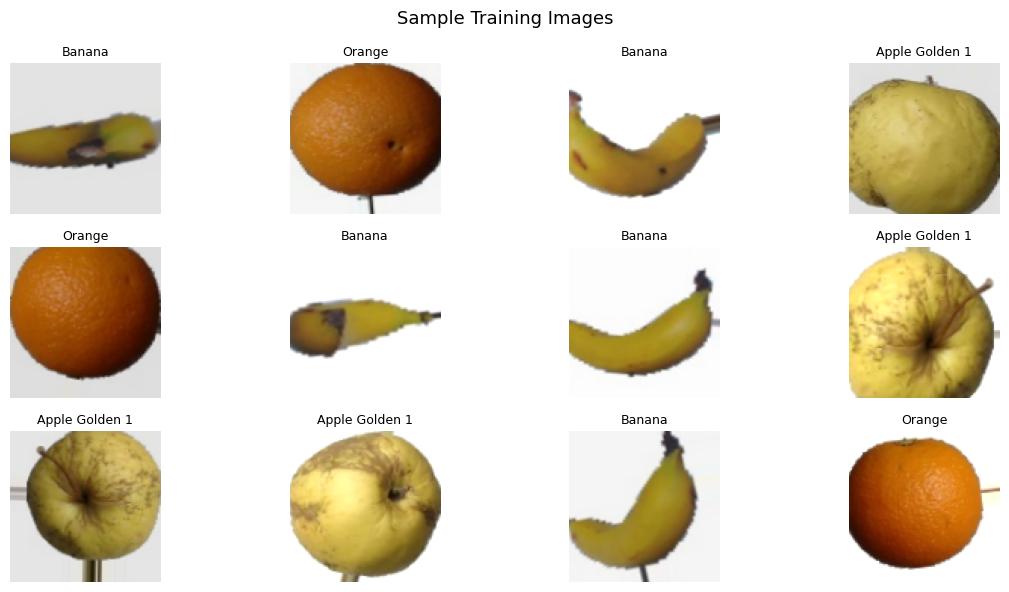

In [5]:
images, labels = next(train_gen)

plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(images[i])
    plt.title(CLASS_NAMES[np.argmax(labels[i])], fontsize=9)
    plt.axis('off')
plt.suptitle("Sample Training Images", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
def build_cnn(num_classes):
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(100,100,3)),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.25),

        # Block 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),
        layers.Dropout(0.3),

        # Classifier head
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = build_cnn(num_classes=len(CLASS_NAMES))
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,860,963 (18.54 MB)

 Trainable params: 4,860,003 (18.54 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.9655 - loss: 0.1061 - val_accuracy: 0.4152 - val_loss: 12.7365 - learning_rate: 0.0010
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.6367 - val_loss: 24.4613 - learning_rate: 0.0010
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - accuracy: 0.9966 - loss: 0.0214 - val_accuracy: 0.4394 - val_loss: 35.2884 - learning_rate: 0.0010
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9928 - loss: 0.0449
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
37/37 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.9966 - loss: 0.0217 - val_accuracy: 0.4394 - val_loss: 35.7235 - learning_rate: 0.0010
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.9983 - loss: 0.0027 - val_accuracy: 0.4187 - val_loss: 51.7197 - learning_rate: 5.0000e-04
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 1.0000 - loss: 0.0020 - val_acc

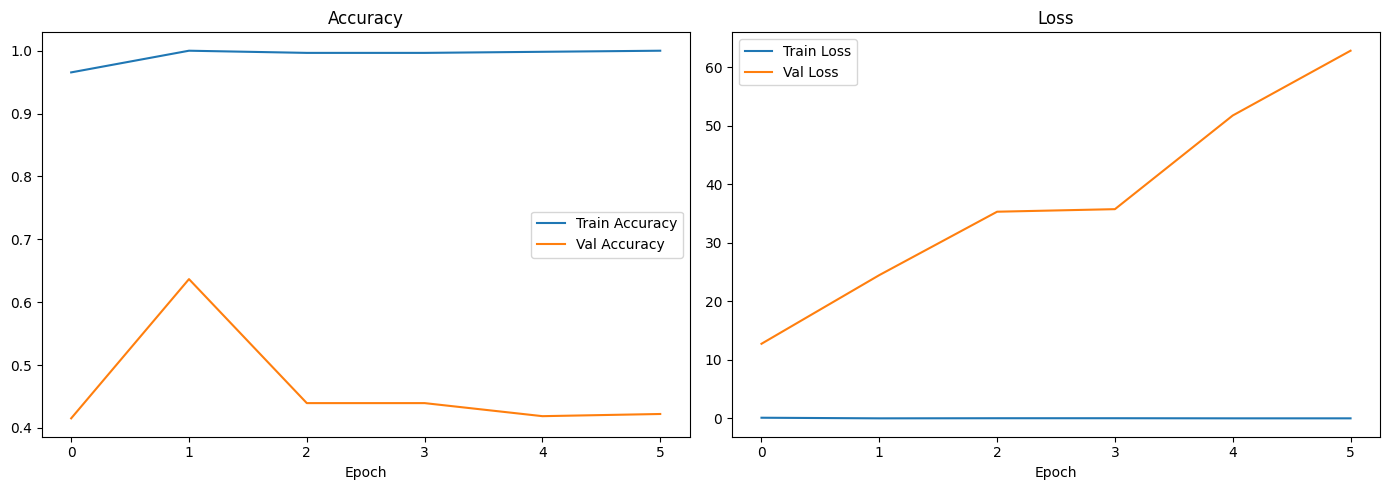

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'],     label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Accuracy'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].plot(history.history['loss'],     label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Loss'); axes[1].legend(); axes[1].set_xlabel('Epoch')

plt.tight_layout()
plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 520ms/step - accuracy: 0.6091 - loss: 12.6505

Test Accuracy: 60.91%
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 524ms/step

Classification Report:
                precision    recall  f1-score   support

Apple Golden 1       0.45      0.81      0.58       160
        Banana       0.85      1.00      0.92       166
        Orange       0.00      0.00      0.00       160

      accuracy                           0.61       486
     macro avg       0.43      0.60      0.50       486
  weighted avg       0.44      0.61      0.50       486



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


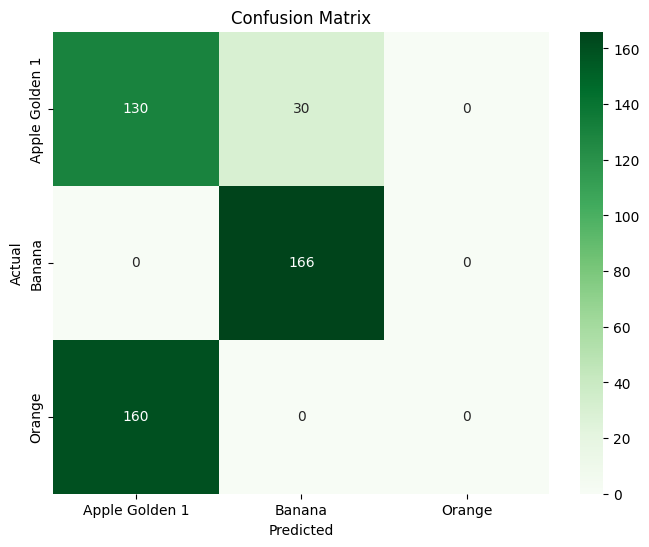

In [9]:
loss, acc = model.evaluate(test_gen)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_pred = np.argmax(model.predict(test_gen), axis=1)
y_true = test_gen.classes

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

In [10]:
base_model = keras.applications.MobileNetV2(
    input_shape=(100, 100, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

tl_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(CLASS_NAMES), activation='softmax')
])

tl_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Phase 1: train head only
tl_model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks)

# Phase 2: unfreeze and fine-tune
base_model.trainable = True
tl_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
tl_model.fit(train_gen, validation_data=val_gen, epochs=10, callbacks=callbacks)

loss, acc = tl_model.evaluate(test_gen)
print(f"\nTransfer Learning Test Accuracy: {acc*100:.2f}%")

/tmp/ipykernel_1423/396971676.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 25s 537ms/step - accuracy: 0.9672 - loss: 0.0950 - val_accuracy: 1.0000 - val_loss: 2.5063e-05 - learning_rate: 0.0010
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 16s 439ms/step - accuracy: 0.9991 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 3.6098e-05 - learning_rate: 0.0010
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 16s 436ms/step - accuracy: 1.0000 - loss: 1.5406e-04 - val_accuracy: 0.9931 - val_loss: 0.0136 - learning_rate: 0.0010
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step - accuracy: 1.0000 - loss: 2.2716e-04
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
37/37 ━━━━━━━━━━━━━━━━━━━━ 16s 439ms/step - accuracy: 1.0000 - loss: 3.3172e-04 - val_accuracy: 0.9965 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 501ms/step - accuracy: 1.0000 - loss: 6.1235e-05 - val_accuracy: 1.0000 - val_loss: 1.7645e-04 - learning_rate: 5.0000e-04
Epo

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step


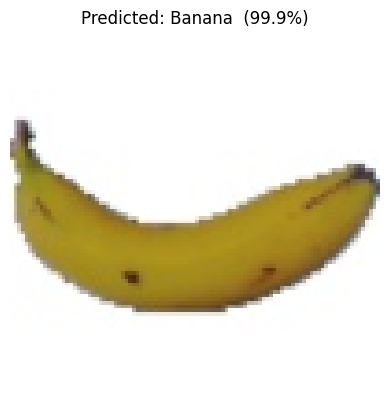

  Apple Golden 1: 0.08%
  Banana: 99.92%
  Orange: 0.00%


In [11]:
from tensorflow.keras.preprocessing import image as keras_image
import os # Import os module to list directory contents

def predict_fruit(img_path, use_tl=False):
    chosen_model = tl_model if use_tl else model
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    arr = keras_image.img_to_array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    preds = chosen_model.predict(arr)[0]
    top   = np.argmax(preds)

    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Predicted: {CLASS_NAMES[top]}  ({preds[top]*100:.1f}%)")
    plt.show()

    for name, prob in zip(CLASS_NAMES, preds):
        print(f"  {name}: {prob*100:.2f}%")

# Find a valid image path dynamically
banana_test_dir = 'fruits_data/test/Banana'
if os.path.exists(banana_test_dir):
    banana_images = os.listdir(banana_test_dir)
    if banana_images:
        first_banana_image = os.path.join(banana_test_dir, banana_images[0])
        predict_fruit(first_banana_image)
    else:
        print(f"Error: No images found in {banana_test_dir}")
else:
    print(f"Error: Directory {banana_test_dir} does not exist.")